# 12b · Set Model dengan Skala Diperbaiki

**Masalah di notebook 12.** Set model berhenti di epoch yang berbeda di tiap fold (4 sampai 11), sehingga **rentang skornya berbeda** antar fold. Saat 5 fold digabung menjadi satu OOF, ambang yang sama berarti hal berbeda di tiap fold, dan KS gabungan turun. Contoh di data penuh, seed 2024: KS per fold 0,389–0,407, tapi KS OOF gabungannya hanya 0,3766. Di `cek_kalibrasi_fold.py`, selisihnya +0,017 untuk set model, sedangkan GBDT dan logreg ≈ 0.

Masalah yang sama ada di **stacking (uji C)**:
- `set_score` baris latih berasal dari 4 model dalam yang skalanya berbeda-beda, jadi fiturnya berisik;
- `set_score` baris validasi adalah rata-rata 4 model itu, sehingga sebarannya **lebih sempit** daripada baris latih. LightGBM belajar ambang di satu sebaran, lalu diuji di sebaran lain.

**Perbaikan:** semua skor dipetakan ke **persentil populasi yang sama**, yaitu baris test (setiap model dalam memprediksi seluruh baris test).

```
baris latih, dari model dalam j    : persentil skor terhadap prediksi test model j
baris validasi & test              : rata-rata logit 4 model dalam → persentil terhadap rata-rata logit di test
```

Hasilnya, baris latih, validasi, dan test punya skala dan sebaran yang sama. Label tetap tidak bocor: baris test tidak berlabel, dan baris validasi tetap tidak pernah dilihat model mana pun.

**Yang dijalankan:**

| Bagian | Isi | Waktu |
|---|---|---|
| Uji A & B ulang | memakai `setmodel_v1` dari notebook 12; OOF **semua** model diperingkat di dalam fold (perlakuan sama) | ± 2 menit, tanpa melatih ulang set model |
| **Uji C v2** ⭐ | stacking bersarang dengan perbaikan skala + plasebo | sama seperti notebook 12 (± 75 menit di mesin Anda) |
| Uji D ulang | ensemble saat ini vs kandidat dengan versi v2 | ± 1 menit |

**Syarat:** notebook 12 sudah dijalankan (`setmodel_v1` ada di `data/preds/`). `seq_models.py` versi baru (ada fungsi `to_pct`, `rank_run_in_fold`).

In [1]:
import gc
import json
import time

import numpy as np
import polars as pl
import torch

import eda_utils as E
import features as F
import modeling as M
import seq_models as Q

E.setup_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

SEEDS = (42, 7, 2024)
STACK_SEEDS = (42, 7, 2024)    # untuk uji cepat: (42,)
SKIP_DONE = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| thread CPU torch:", torch.get_num_threads())
assert hasattr(Q, "rank_run_in_fold"), "seq_models.py masih versi lama, ganti dengan versi baru"

meta = json.loads((M.FEAT_DIR / "features_v1.json").read_text())
FEAT, CATS, EC = meta["features"], meta["categorical"], meta["groups"]["ecommerce"]
train = pl.read_parquet(M.FEAT_DIR / "train_v1.parquet")
test = pl.read_parquet(M.FEAT_DIR / "test_v1.parquet")
y = train["target"].to_numpy()
SEG = train["segment"].to_numpy()
folds = M.fold_table(train)

CORE = {"lgbm": "lgbm_tuned", "xgb": "xgb_v1", "cat": "cat_v1", "logreg": "logreg_v1"}
RUNS = {k: M.run_from_disk(v, y) for k, v in CORE.items()}
LGB = RUNS["lgbm"]
P_LGB = {k: v for k, v in LGB["params"].items() if k != "random_state"}

assert (M.PRED_DIR / "setmodel_v1_meta.json").exists(), "jalankan notebook 12 dulu (setmodel_v1)"
SET = M.run_from_disk("setmodel_v1", y)
SET_R = Q.rank_run_in_fold(SET, folds, y)          # OOF diperingkat di dalam fold
print(f"e-commerce: {meta['ecommerce_source']}")
print("set model KS per seed, mentah      :", {s: round(v, 4) for s, v in SET["ks_by_seed"].items()})
print("set model KS per seed, rank per fold:", {s: round(v, 4) for s, v in SET_R["ks_by_seed"].items()})

device: cpu | thread CPU torch: 4
e-commerce: ecommerce_transactions.csv
set model KS per seed, mentah      : {42: 0.3903, 7: 0.3868, 2024: 0.3766}
set model KS per seed, rank per fold: {42: 0.3916, 7: 0.3898, 2024: 0.3936}


## 1. Uji A & B ulang (perlakuan sama untuk semua model)

OOF **semua** model di sini diperingkat di dalam tiap fold, bukan hanya set model. Untuk LightGBM dan logreg langkah ini praktis tidak mengubah apa-apa (selisih ≈ 0 di `cek_kalibrasi_fold.py`), tapi perlakuannya jadi simetris.

In [2]:
EC_LGB = Q.rank_run_in_fold(M.train_lgb_cv(train, test, EC, [], seeds=SEEDS, params=P_LGB, verbose=False), folds, y)
EC_LR = Q.rank_run_in_fold(M.train_cv("logreg", train, test, EC, [], seeds=SEEDS, verbose=False), folds, y)

def ks_row(name, r, seeds=SEEDS):
    s = [x for x in seeds if x in r["seeds"]]
    return dict(model=name, **{f"ks_s{x}": r["ks_by_seed"][x] for x in s},
                ks_rata2_per_seed=np.mean([r["ks_by_seed"][x] for x in s]),
                ks_oof_gabungan=M.ks_score(y, np.mean([r["oof_by_seed"][x] for x in s], axis=0)))

def cmp_table(cmps, noise=0.0015):
    out = []
    for n, c in cmps.items():
        ns = c["per_seed"].height
        out.append(dict(perbandingan=n, delta_oof_gabungan=c["delta_oof"],
                        **{f"d_s{s}": d for s, d in zip(c["per_seed"]["seed"], c["per_seed"]["delta"])},
                        delta_rata2=c["delta_seed_mean"], seed_naik=f"{c['n_seed_positive']}/{ns}",
                        keputusan=M.verdict(c, noise=noise) if ns >= 3 else "perlu 3 seed"))
    return pl.DataFrame(out).with_columns(pl.col(pl.Float64).round(4))

display(pl.DataFrame([ks_row("LightGBM ec_*", EC_LGB), ks_row("logreg ec_*", EC_LR),
                      ks_row("set model (mentah, notebook 12)", SET), ks_row("set model (rank per fold)", SET_R)])
          .with_columns(pl.col(pl.Float64).round(4)))
B_REF = M.blend({"lgbm_ec": EC_LGB, "logreg_ec": EC_LR}, y, seeds=list(SEEDS))
B_SET = M.blend({"lgbm_ec": EC_LGB, "set": SET_R}, y, seeds=list(SEEDS))
cmp_table({"A: set model vs LightGBM ec_*": M.compare_runs(EC_LGB, SET_R, y),
           "A: set model vs logreg ec_*": M.compare_runs(EC_LR, SET_R, y),
           "B: (LGBM ec + set) vs (LGBM ec + logreg ec)": M.compare_runs(B_REF, B_SET, y)})

model,ks_s42,ks_s7,ks_s2024,ks_rata2_per_seed,ks_oof_gabungan
str,f64,f64,f64,f64,f64
"""LightGBM ec_*""",0.3846,0.3855,0.3857,0.3853,0.3853
"""logreg ec_*""",0.3884,0.3889,0.3888,0.3887,0.3885
"""set model (mentah, notebook 12)""",0.3903,0.3868,0.3766,0.3846,0.394
"""set model (rank per fold)""",0.3916,0.3898,0.3936,0.3917,0.3952


perbandingan,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,str,str
"""A: set model vs LightGBM ec_*""",0.01,0.007,0.0043,0.0079,0.0064,"""3/3""","""jelas"""
"""A: set model vs logreg ec_*""",0.0067,0.0032,0.0009,0.0049,0.003,"""3/3""","""tipis"""
"""B: (LGBM ec + set) vs (LGBM ec + logreg ec)""",0.0043,0.004,0.0014,0.0033,0.0029,"""3/3""","""tipis"""


## 2. Uji C v2: stacking bersarang dengan skala diperbaiki ⭐

Data item disiapkan lagi (sama seperti notebook 12), lalu stacking dijalankan dengan `calibrate=True`. Log tiap fold sekarang juga mencetak **KS skor set model sendiri** di baris latih (OOF dalam yang digabung) dan di baris validasi. Kalau perbaikannya bekerja, kedua angka ini seharusnya mirip. Di versi lama, skor baris latih tertekan oleh beda skala antar model dalam.

In [3]:
t = time.time()
T = F.load_tables(E.load, E.lazy)
A_tr = Q.to_arrays(Q.item_table(T["ecommerce"], E.load("train_applications"), T["ecom_cat_medians"]), train["customer_id"].to_list())
A_te = Q.to_arrays(Q.item_table(T["ecommerce"], E.load("test_applications"), T["ecom_cat_medians"]), test["customer_id"].to_list())
ARR = Q.concat_arrays(A_tr, A_te)
TEST_IDX = np.arange(train.height, train.height + test.height)
del T
gc.collect()
print(f"siap dalam {time.time() - t:.0f}s | array item {ARR['num'].shape}")

siap dalam 15s | array item (4359817, 8)


In [4]:
done = all((M.PRED_DIR / f"{n}_meta.json").exists() for n in ("lgbm_stack_set_v2", "lgbm_stack_placebo_v2"))
if SKIP_DONE and done:
    STACK, PLACEBO = M.run_from_disk("lgbm_stack_set_v2", y), M.run_from_disk("lgbm_stack_placebo_v2", y)
    STACK_FOLDS = pl.DataFrame(STACK["meta"]["fold_table"])
    print(f"run stacking v2 dimuat dari disk (dilatih {STACK['meta'].get('minutes')} menit)")
else:
    t = time.time()
    STACK, PLACEBO = Q.stacked_lgb_cv(train, test, FEAT, CATS, ARR, folds, STACK_SEEDS, P_LGB, TEST_IDX,
                                      device=DEVICE, calibrate=True)
    STACK_FOLDS = STACK["folds"]
    mins = round((time.time() - t) / 60, 1)
    for name, r in (("lgbm_stack_set_v2", STACK), ("lgbm_stack_placebo_v2", PLACEBO)):
        M.save_run(name, train, test, r, extra=dict(kind="lgbm_stacking", feature_version="v1+set_score_pct",
                                                    minutes=mins, fold_table=r["folds"].to_dicts()))
print("Per fold: KS LightGBM, porsi gain set_score (%), KS skor set model di baris latih vs validasi:")
display(STACK_FOLDS.with_columns(pl.col(pl.Float64).round(4)))

[stack] seed 42 fold 1: KS 0.5207 (plasebo 0.5207) | gain set_score 16.9% | KS skor latih/val 0.3896/0.4032 | 628s
[stack] seed 42 fold 2: KS 0.5322 (plasebo 0.5284) | gain set_score 16.6% | KS skor latih/val 0.3932/0.3848 | 1307s
[stack] seed 42 fold 3: KS 0.5413 (plasebo 0.5375) | gain set_score 16.1% | KS skor latih/val 0.3811/0.4168 | 1727s
[stack] seed 42 fold 4: KS 0.5211 (plasebo 0.5169) | gain set_score 14.4% | KS skor latih/val 0.3926/0.3758 | 2055s
[stack] seed 42 fold 5: KS 0.5144 (plasebo 0.5092) | gain set_score 16.1% | KS skor latih/val 0.3967/0.3859 | 2378s
[stack] seed 7 fold 1: KS 0.5267 (plasebo 0.5254) | gain set_score 13.7% | KS skor latih/val 0.3925/0.3975 | 2624s
[stack] seed 7 fold 2: KS 0.5244 (plasebo 0.5215) | gain set_score 13.6% | KS skor latih/val 0.3886/0.4108 | 2857s
[stack] seed 7 fold 3: KS 0.5270 (plasebo 0.5213) | gain set_score 13.4% | KS skor latih/val 0.3861/0.3987 | 3090s
[stack] seed 7 fold 4: KS 0.5292 (plasebo 0.5307) | gain set_score 13.2% | K

seed,fold,ks,gain_set_score_pct,ks_skor_latih,ks_skor_val
i64,i64,f64,f64,f64,f64
42,1,0.5207,16.8866,0.3896,0.4032
42,2,0.5322,16.558,0.3932,0.3848
42,3,0.5413,16.0999,0.3811,0.4168
42,4,0.5211,14.4063,0.3926,0.3758
42,5,0.5144,16.1315,0.3967,0.3859
7,1,0.5267,13.7041,0.3925,0.3975
7,2,0.5244,13.6332,0.3886,0.4108
7,3,0.527,13.4045,0.3861,0.3987
7,4,0.5292,13.2194,0.3949,0.3897


Noise uji C (maks |Δ plasebo| per seed, minimal 0,0015): 0.0022


perbandingan,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,str,str
"""lgbm_tuned + set_score v2""",0.0004,0.0016,0.0039,0.0009,0.0022,"""3/3""","""tidak"""
"""lgbm_tuned + kolom acak (plasebo v2)""",-0.0009,-0.0009,0.0022,0.0003,0.0005,"""2/3""","""tidak"""
"""set_score v2 vs plasebo v2""",0.0013,0.0026,0.0017,0.0007,0.0017,"""3/3""","""tidak"""
"""v2 vs v1 (efek perbaikan skala)""",0.0008,0.0016,0.0026,0.0012,0.0018,"""3/3""","""tidak"""


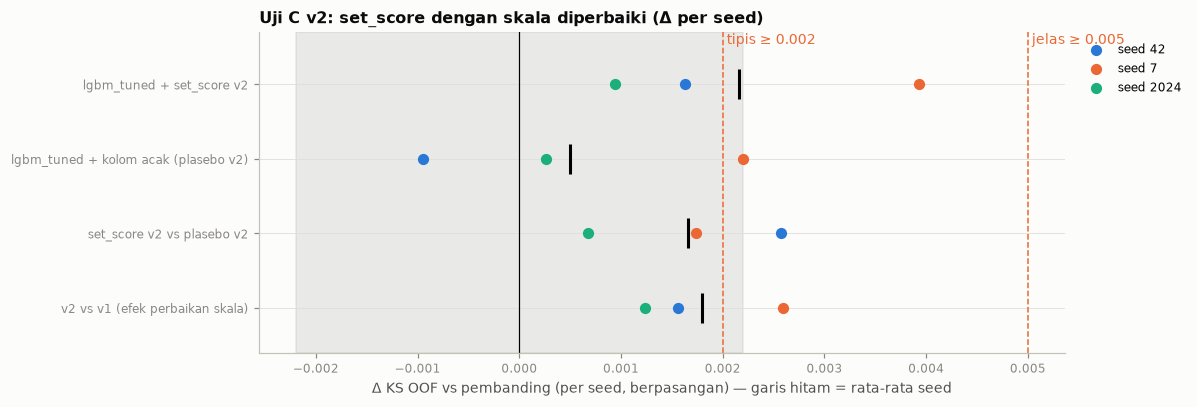

In [5]:
CMP_C = {"lgbm_tuned + set_score v2": M.compare_runs(LGB, STACK, y, SEG),
         "lgbm_tuned + kolom acak (plasebo v2)": M.compare_runs(LGB, PLACEBO, y, SEG),
         "set_score v2 vs plasebo v2": M.compare_runs(PLACEBO, STACK, y, SEG)}
if (M.PRED_DIR / "lgbm_stack_set_v1_meta.json").exists():
    V1 = M.run_from_disk("lgbm_stack_set_v1", y)
    CMP_C["v2 vs v1 (efek perbaikan skala)"] = M.compare_runs(V1, STACK, y, SEG)
NOISE_C = max(0.0015, float(CMP_C["lgbm_tuned + kolom acak (plasebo v2)"]["per_seed"]["delta"].abs().max()))
print(f"Noise uji C (maks |Δ plasebo| per seed, minimal 0,0015): {NOISE_C:.4f}")
display(cmp_table(CMP_C, noise=NOISE_C))
M.plot_paired_deltas(CMP_C, list(CMP_C), noise=NOISE_C, title="Uji C v2: set_score dengan skala diperbaiki (Δ per seed)")

In [6]:
rows = []
for g in sorted(set(SEG)):
    m = SEG == g
    for name, r in (("+ set_score v2", STACK), ("+ plasebo v2", PLACEBO)):
        d = {s: M.ks_score(y[m], r["oof_by_seed"][s][m]) - M.ks_score(y[m], LGB["oof_by_seed"][s][m]) for s in STACK["seeds"]}
        rows.append(dict(segmen=g, n=int(m.sum()), kolom_tambahan=name, **{f"d_s{s}": v for s, v in d.items()},
                         delta_rata2=np.mean(list(d.values())), seed_naik=f"{sum(v > 0 for v in d.values())}/{len(d)}"))
print("Δ KS per segmen per seed vs lgbm_tuned:")
pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))

Δ KS per segmen per seed vs lgbm_tuned:


segmen,n,kolom_tambahan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik
str,i64,str,f64,f64,f64,f64,str
"""A_no_history""",21000,"""+ set_score v2""",0.0003,0.0003,0.0024,0.001,"""3/3"""
"""A_no_history""",21000,"""+ plasebo v2""",-0.0008,-0.0027,-0.0009,-0.0015,"""0/3"""
"""B_apps_no_installments""",2688,"""+ set_score v2""",-0.018,-0.0039,-0.0081,-0.01,"""0/3"""
"""B_apps_no_installments""",2688,"""+ plasebo v2""",-0.0079,0.0059,-0.0059,-0.0026,"""1/3"""
"""C_has_installments""",46312,"""+ set_score v2""",-0.0009,0.0028,0.0009,0.0009,"""2/3"""
"""C_has_installments""",46312,"""+ plasebo v2""",-0.0048,0.0009,-0.0,-0.0013,"""1/3"""


## 3. Uji D ulang: ensemble saat ini

Sama seperti notebook 12. Bedanya, anggota set model memakai OOF yang diperingkat per fold, dan versi stacking memakai v2.

KS OOF ensemble saat ini (3 seed): 0.5254 | noise uji D: 0.0015


perbandingan,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,str,str
"""ensemble + set model""",-0.0042,-0.0037,-0.0029,-0.0036,-0.0034,"""0/3""","""tidak"""
"""ensemble, lgbm → lgbm + set_score v2""",0.0006,0.0014,0.0001,0.0001,0.0005,"""3/3""","""tidak"""
"""ensemble, lgbm → plasebo v2""",-0.0003,-0.0003,-0.0001,-0.0,-0.0001,"""0/3""","""tidak"""
"""ensemble + set model, bobot jujur""",-0.0019,-0.0011,-0.0019,-0.0018,-0.0016,"""0/3""","""tidak"""


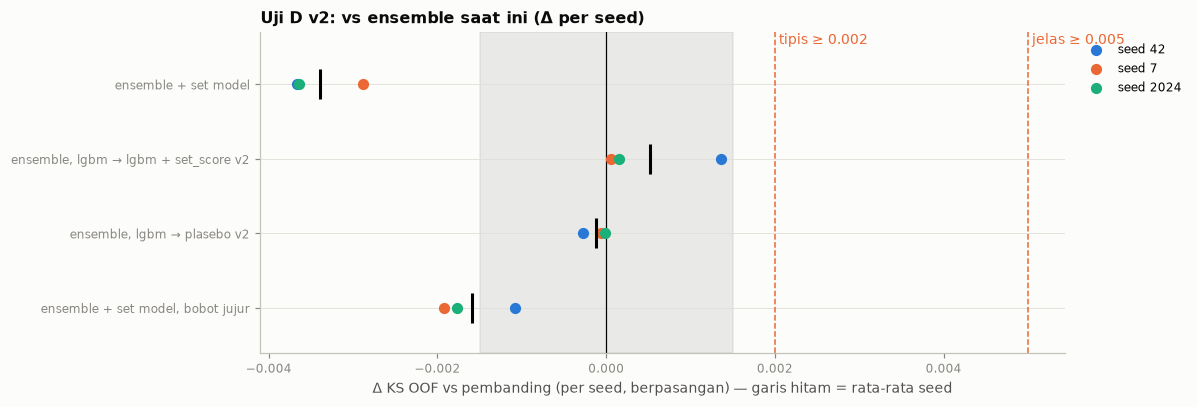

Bobot terpilih per fold (validasi bersarang):


seed,lgbm,xgb,cat,logreg,set
i64,f64,f64,f64,f64,f64
42,0.1,0.1,0.5,0.2,0.1
42,0.2,0.1,0.3,0.4,0.0
42,0.2,0.1,0.4,0.3,0.0
42,0.2,0.1,0.3,0.4,0.0
42,0.2,0.1,0.5,0.2,0.0
7,0.1,0.3,0.4,0.2,0.0
7,0.2,0.3,0.2,0.3,0.0
7,0.1,0.0,0.4,0.4,0.1
7,0.3,0.1,0.1,0.4,0.1


In [7]:
D_SEEDS = [s for s in SEEDS if s in STACK["seeds"]]
REF_D = M.blend({k: RUNS[k] for k in CORE}, y, seeds=D_SEEDS)
BL = {"ensemble + set model": M.blend({**{k: RUNS[k] for k in CORE}, "set": SET_R}, y, seeds=D_SEEDS),
      "ensemble, lgbm → lgbm + set_score v2": M.blend({**{k: RUNS[k] for k in CORE}, "lgbm": STACK}, y, seeds=D_SEEDS),
      "ensemble, lgbm → plasebo v2": M.blend({**{k: RUNS[k] for k in CORE}, "lgbm": PLACEBO}, y, seeds=D_SEEDS)}
BL["ensemble + set model, bobot jujur"] = M.nested_blend({**{k: RUNS[k] for k in CORE}, "set": SET_R}, y, "lgbm",
                                                         seeds=D_SEEDS, step=0.1, max_other=0.9)
CMP_D = {n: M.compare_runs(REF_D, b, y, SEG) for n, b in BL.items()}
NOISE_D = max(0.0015, float(CMP_D["ensemble, lgbm → plasebo v2"]["per_seed"]["delta"].abs().max()))
print(f"KS OOF ensemble saat ini ({len(D_SEEDS)} seed): {REF_D['ks_oof']:.4f} | noise uji D: {NOISE_D:.4f}")
display(cmp_table(CMP_D, noise=NOISE_D))
M.plot_paired_deltas(CMP_D, list(CMP_D), noise=NOISE_D, title="Uji D v2: vs ensemble saat ini (Δ per seed)")
print("Bobot terpilih per fold (validasi bersarang):")
display(BL["ensemble + set model, bobot jujur"]["fold_weights"])

## 4. Keputusan

In [8]:
pool = [n for n in CMP_D if n != "ensemble, lgbm → plasebo v2" and CMP_D[n]["per_seed"].height >= 3]
best = max(pool, key=lambda n: CMP_D[n]["delta_oof"]) if pool else None
c = CMP_C["lgbm_tuned + set_score v2"]
print(f"Uji C v2 (penentu): {M.verdict(c, noise=NOISE_C) if c['per_seed'].height >= 3 else 'perlu 3 seed'}")
if best:
    V_D = M.verdict(CMP_D[best], noise=NOISE_D)
    print(f"Uji D kandidat terbaik: {best} | Δ OOF gabungan {CMP_D[best]['delta_oof']:+.4f} | keputusan: {V_D}")
    if V_D in ("jelas", "tipis") and best != "ensemble + set model, bobot jujur":
        pick = BL[best]
        pick.update(features=[], params=pick.get("weights", {}), best_iters=[0])
        M.save_run("ensemble_set_v2", train, test, pick, extra=dict(blend=best, delta_vs_ensemble_v1=CMP_D[best]["delta_oof"]))
        ss = pl.read_parquet(E.PQ_DIR / "sample_submission.parquet")
        M.make_submission(test["application_id"], pick["test_pred"], ss, M.SUB_DIR / "sub_v6_ensemble_set.csv")
    elif V_D in ("jelas", "tipis"):
        print("Yang lolos adalah bobot jujur; bobotnya berbeda tiap fold, jadi perlu dibahas dulu sebelum dibuat submission.")
    else:
        print("Tidak lolos → ensemble saat ini (sub_v4) tetap dipakai.")

Uji C v2 (penentu): tidak
Uji D kandidat terbaik: ensemble, lgbm → lgbm + set_score v2 | Δ OOF gabungan +0.0006 | keputusan: tidak
Tidak lolos → ensemble saat ini (sub_v4) tetap dipakai.
